<a href="https://colab.research.google.com/github/mullinskatie7-source/katherine-mullins.github.io/blob/main/Katherine_Mullins_Regression_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 1: Markdown
# Regression Analysis of Home Prices

**Engineer:** Katherine Mullins

**Completion Date:** 11/02/2026

**Class:** EGN3443

**Assignment #:** 11

**Tool Used:** Colab / Python

## Problem Description

The objective of this analysis is to determine whether a home's living square footage, represented by square foot living (sqft_living), is useful for predicting its sale price.

The variables used in the simple linear regression are:

	Independent variable, (x): living area of the house square foot living, measured in square feet
	Dependent variable, (y): home sale price (price), measured in dollars
The simple linear regression model is:

$$
\hat{y} = b_0 + b_1x
$$

where:

$$
\hat{y} = \text{predicted home price}
$$

$$
b_0 = \text{regression intercept}
$$

$$
b_1 = \text{regression slope}
$$

$$
x = \text{living area in square feet}
$$

The analysis evaluates whether a statistically significant linear relationship exists between living area and home price and whether living area alone provides sufficient predictive ability for estimating property values.


## Methodology

The housing dataset was imported into Python, and the variables price and square foot living were selected for analysis. The data were first examined using a scatter plot of home price versus living area. This visualization was used to determine whether a visible linear relationship existed between the variables and to identify the general direction and strength of the relationship.

The Pearson correlation coefficient was calculated to measure the strength of the linear association between living area and price.

A simple linear regression model was then developed using living area as the predictor and home price as the response variable. The regression slope, intercept, coefficient of determination (R^2) and p-value were calculated.

The hypotheses for the regression slope were:
$$
H_0 ∶ β_1=0
$$
$$
and
$$
$$
H_1 ∶ β_1≠0
$$

The null hypothesis states that living square footage has no linear relationship with home price. The alternative hypothesis states that living square footage is significantly related to home price.

A significance level of:
$$
α=0.05
$$
was used. If the p-value associated with the regression slope was less than 0.05, the null hypothesis was rejected.


Please upload your 'Housing.csv' file:


Saving Housing.csv.zip to Housing.csv (1).zip
           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7229300521  20141013T000000  231300.0         2       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8        1680              0   

   y

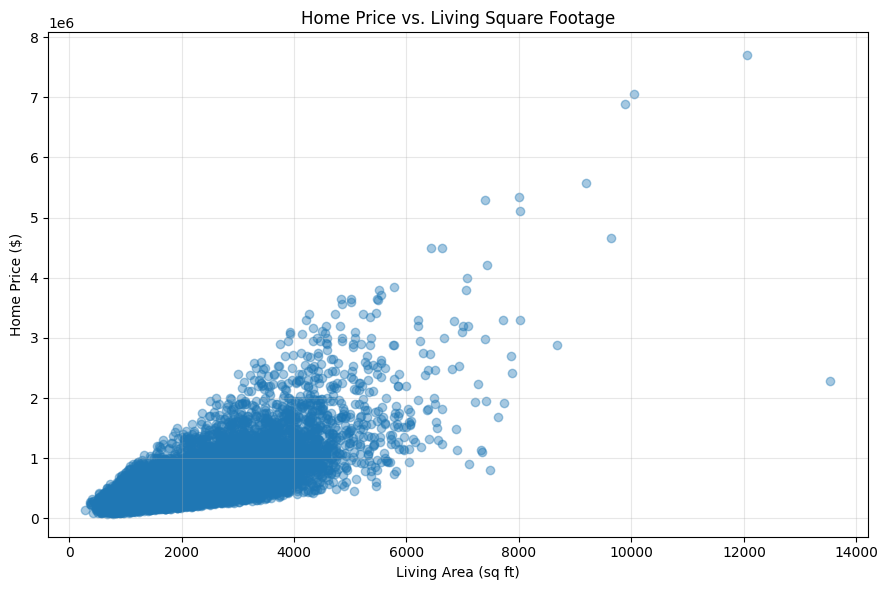

Pearson correlation: 0.7020346040056653
Correlation p-value: 0.0
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.493
Model:                            OLS   Adj. R-squared:                  0.493
Method:                 Least Squares   F-statistic:                 2.100e+04
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:41:03   Log-Likelihood:            -3.0027e+05
No. Observations:               21613   AIC:                         6.005e+05
Df Residuals:                   21611   BIC:                         6.006e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

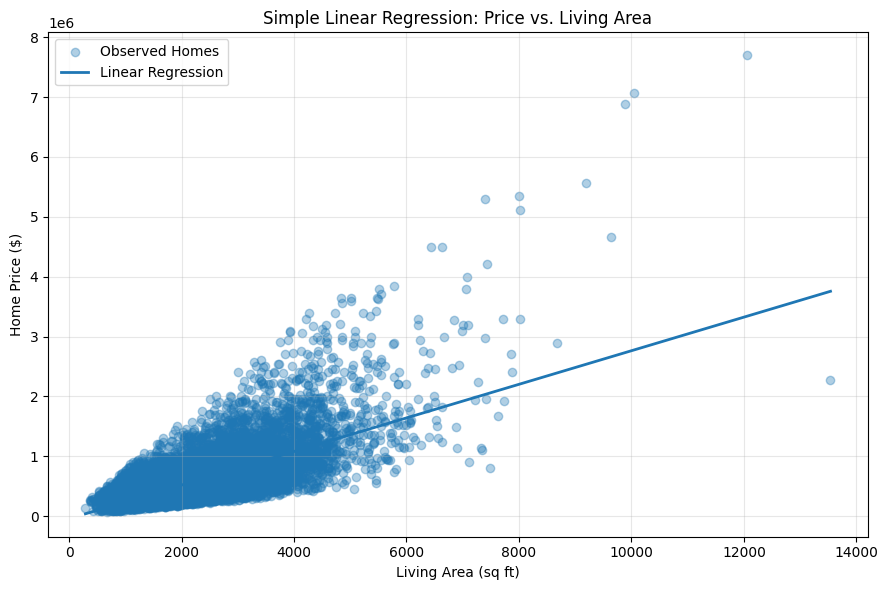

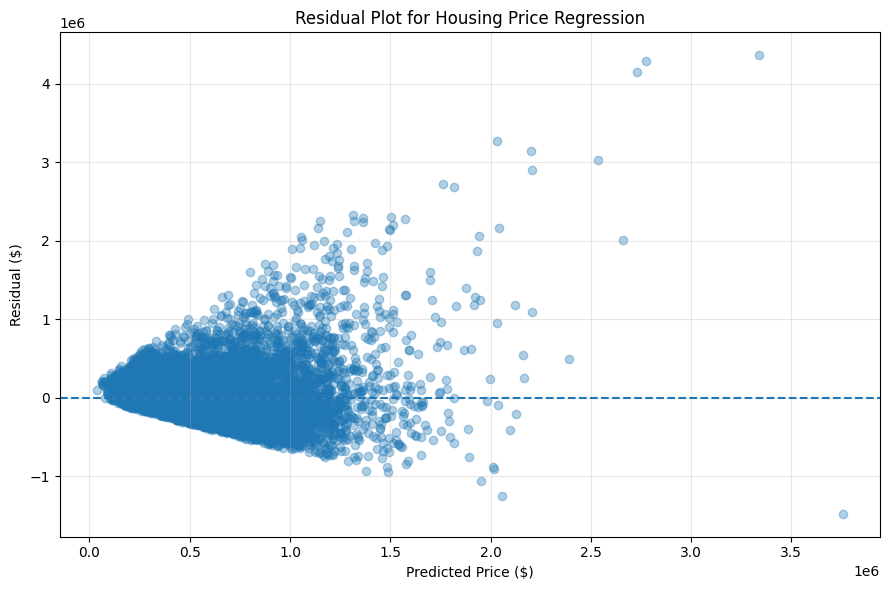


Correlation with Price:
price            1.000000
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585378
bathrooms        0.525136
view             0.397294
sqft_basement    0.323816
bedrooms         0.308377
lat              0.307003
waterfront       0.266370
floors           0.256793
yr_renovated     0.126434
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054011
condition        0.036361
long             0.021626
id              -0.016762
zipcode         -0.053201
Name: price, dtype: float64


In [3]:
# Step 2: Import required modules and define constants
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

from google.colab import files
import os

# Prompt to upload 'Housing.csv'
if not os.path.exists('Housing.csv'):
    print("Please upload your 'Housing.csv' file:")
    uploaded = files.upload()
else:
    print("'Housing.csv' is already uploaded and ready to use!")

# Load the dataset from the available zip archive
df = pd.read_csv("/content/Housing.csv.zip")

# Display basic information
print(df.head())
print(df.shape)
print(df[['price', 'sqft_living']].describe())

# Select variables
x = df['sqft_living']
y = df['price']

# Step 3: Scatter plot
plt.figure(figsize=(9, 6))

plt.scatter(x, y, alpha=0.4)

plt.xlabel("Living Area (sq ft)")
plt.ylabel("Home Price ($)")
plt.title("Home Price vs. Living Square Footage")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 4: Correlation
r, corr_p = stats.pearsonr(x, y)

print("Pearson correlation:", r)
print("Correlation p-value:", corr_p)

# Step 5: Simple Linear Regression
X = sm.add_constant(x)

model = sm.OLS(y, X).fit()

print(model.summary())

intercept = model.params['const']
slope = model.params['sqft_living']
r_squared = model.rsquared
p_value = model.pvalues['sqft_living']

print("\nIntercept:", intercept)
print("Slope:", slope)
print("R-squared:", r_squared)
print("Slope p-value:", p_value)

# Step 6: Scatter Plot with Regression Line
predicted_price = model.predict(X)

plt.figure(figsize=(9, 6))

plt.scatter(
    x,
    y,
    alpha=0.35,
    label="Observed Homes"
)

# Sort x values so regression line is drawn cleanly
order = np.argsort(x)

plt.plot(
    x.iloc[order],
    predicted_price.iloc[order],
    linewidth=2,
    label="Linear Regression"
)

plt.xlabel("Living Area (sq ft)")
plt.ylabel("Home Price ($)")
plt.title("Simple Linear Regression: Price vs. Living Area")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 7: Residual Plot
residuals = y - predicted_price

plt.figure(figsize=(9, 6))

plt.scatter(
    predicted_price,
    residuals,
    alpha=0.35
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Price ($)")
plt.ylabel("Residual ($)")
plt.title("Residual Plot for Housing Price Regression")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 8: Correlations with other numeric variables
numeric_df = df.select_dtypes(include=np.number)

correlations = (
    numeric_df.corr()["price"]
    .sort_values(ascending=False)
)

print("\nCorrelation with Price:")
print(correlations)